# clm pre-screen and debug tool
## setting up
1. make sure the 12V DC power supply is OFF
2. carefully mount the DUT clm on the test board; place heatsink on DUT clm
3. clean and inspect clm output facets
4. connect clm output fibers to opm input (with attenuator!) in order of left to right --> powrt low to high (Remember: never connect, disconnect fiber when the clm ON)
5. enable 12V power supply. Now the power supply should draw ~0.6A and the green LEDs on the LKM board should light up. When in doubt, ask for help
## general comments on running tests
* if/when you are new to this, and the notebook is not fully debugged, it may be a good idea to step through the cells one at a time from top to bottom by clicking on the 'play' icon

## load Python libs

In [1]:
# -*- coding: utf-8 -*-
"""
Created on Tue Apr 28 11:29:58 2026

@author: MountainViewLabUser
"""
import os
import sys
from tqdm import tqdm
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
#import ips_clm_tile_control
import time
from datetime import datetime, timezone
import pyvisa as visa
import yaml
import pickle
import random

#sys.path.append(r'C:\Users\MountainViewLabUser\gitrepos\instrument-drivers\src')
sys.path.append(r'C:\Users\MountainViewLabUser\gitrepos\instrument-drivers\src\instrument_drivers\devices')
#DRIVER_FOLDER = r"C:\Users\MountainViewLabUser\xingpan\scripts\instr"
#if DRIVER_FOLDER not in sys.path:
#    sys.path.append(DRIVER_FOLDER)
from keysight_N7745c_opm import KeysightN7745C as OPM

#DRIVER_FOLDER = r"C:\Users\MountainViewLabUser\gitrepos\instrument-drivers"
#if DRIVER_FOLDER not in sys.path:
#    sys.path.append(DRIVER_FOLDER)
#DRIVER_FOLDER = r'C:\Users\MountainViewLabUser\gitrepos\instrument-drivers\src\instrument_drivers'
#if DRIVER_FOLDER not in sys.path:
#    sys.path.append(DRIVER_FOLDER)
#from Keysight_N776xC import KeysightN776xC as VOA

#from Thorlabs_PM101 import ThorPM101

venv_scripts = r'C:\Users\MountainViewLabUser\gitrepos\cmis-host-controller\.venv\Scripts'
if os.path.exists(venv_scripts):
    os.add_dll_directory(venv_scripts)
    
import concurrent.futures
MARLOW_API_PATH=r'C:\Users\MountainViewLabUser\gitrepos\cmis-host-controller\src\cmis_host\platform\clm\scripts'
if MARLOW_API_PATH not in sys.path:
    sys.path.append(MARLOW_API_PATH)
import marlow_clm_control_api as mca
from  pptx_maker import PresentationManager

#from pandasgui import show
sns.set_palette("bright")

def export_to_yaml_file(dataDir,dict_fru_revised,sn='dummy',operator='dummy'):
    '''
    '''
    os.chdir(dataDir)
    t0 = datetime.now()
    timeStamp = t0.strftime("%Y-%m-%d-%H-%M-%S")

    for k,dictToDump in dict_fru_revised.items():
        yaml_string = yaml.dump(dictToDump)
        yamlFileName='_'.join([sn,f'tile{k}',dictToDump['serial_number'],operator,timeStamp,'.yaml'])
        with open(yamlFileName, 'w') as file:
            yaml.dump(dictToDump, file, default_flow_style=False)
        
    return 0

rm=visa.ResourceManager()

In [38]:
venv_scripts = r'C:\Users\MountainViewLabUser\gitrepos\cmis-host-controller\.venv\Scripts'
if os.path.exists(venv_scripts):
    os.add_dll_directory(venv_scripts)
    
import concurrent.futures
#MARLOW_API_PATH=r'C:\Users\XingPan\gitrepos\congo-clm-fw\cmis-host-controller\src\cmis_host\platform\clm\scripts'
MARLOW_API_PATH=r'C:\Users\MountainViewLabUser\gitrepos\cmis-host-controller\src\cmis_host\platform\clm\scripts'
if MARLOW_API_PATH not in sys.path:
    sys.path.append(MARLOW_API_PATH)
import marlow_clm_control_api as mca

In [39]:
rm.list_resources()

('TCPIP::100.65.87.253::INSTR',)

## create opm voa and test board objects
(Note: the clm Python API has implemented a auto_scan function and the aadvark sn need not to be accurate)

In [40]:
VOA_ADDRESS='USB0::0x2A8D::0x5901::MY63800685::3::INSTR'
#voa=VOA(VOA_ADDRESS)
#print(voa.query('*IND?'))

OPM_ADDRESS = 'TCPIP::100.65.87.253::INSTR'
opm = OPM(OPM_ADDRESS)
opm.connect()

#opm_thorlab_address='USB0::0x1313::0x8075::P5007568::INSTR'

#opm_thorlab=ThorPM101(opm_thorlab_address)

'Keysight Technologies,N7745C,MY59701072,V3.520'

In [23]:

testBoardType='EVK' #'KLM', 'CNT', 'EVK','CLM-M'
AARDVARK_SN_P0=2239820367 # 2239867798 #2239836767 # 
AARDVARK_SN_Io=2239813795 # 2239880394 #2239833479 # 
tb=mca.get_testboard(AARDVARK_SN_P0 = AARDVARK_SN_P0,AARDVARK_SN_Io = AARDVARK_SN_Io,AARDVARK_SN_P1 =2239789566,testBoardType=testBoardType)

## Please provide information

In [24]:
sn='nnnn' # sn of the clm package
operator='xing' # name of operator
#############
'''
information below need not to be changed. if not sure, please check with TPM or responsible engineer
'''
dir_fw=r'C:\Users\MountainViewLabUser\gitrepos\clm_bin_files\bin_files'
#filename_fw='clm_rel_marlow_tile_v1.8.bin'
filename_fw='clm_rel_marlow_tile_v1.14.bin'
#filename_fw='clm_rel_marlow_tile_v1.11.bin'
#filename_fw='clm_rel_marlow_tile_v1.10-TEST-8_lsb_amplitude.bin'
#filename_fw='clm_rel_marlow_tile_v1.10.bin'
#filename='clm_rel_marlow_tile_v1.10-TEST-8_dac_amplitude.bin'
#filename='clm_rel_marlow_tile_v1.10-TEST_25_dac_amplitude.bin'

power_tgt=12
I_VOA_0=15
bRevise_init_Tpic=True

kps=[0.2,0.2,0.2]
ditherAmp=3

lambda0_voa=1310
attn0_dB=20

In [41]:
'''
setup VOA, opm
'''
for ch in range(4):
    voa.set_attenuation(1+ch*2,attn0_dB)
    voa.set_wavelength(1+ch*2,lambda0_voa)
    voa.enable_channel(1+ch*2,'ON')
    voa.set_power_control_mode(1+ch*2,'OFF')
    time.sleep(0.2)

NameError: name 'voa' is not defined

## read back some basic clm info

In [25]:
dir_main=r'C:\Users\MountainViewLabUser\clm_screen_n_debug'
jobDesc=f'clm prescreen test report for {sn}'

now = datetime.now()
time_test_start = now.strftime("%Y-%m-%d-%H-%M")
time_test_date=now.strftime("%Y-%m-%d")
datadir=dir_main+'\\'+sn+'_'+time_test_date
try:
    os.mkdir(datadir)
except:
    pass

dict_fw=mca.get_tile_fw_version(tb)
idx_tiles=[k-0x60 for k in dict_fw.keys()]

dict_tile_info={}
for idxTile in idx_tiles:
    tile=tb.module.packages[0].tiles[idxTile]
    dict_fru=mca.read_fru_info(tile)
    dict_tile_info.update({idxTile:{'FW':dict_fw[0x60+idxTile],
                                    'tile_sn':dict_fru['serial_number']}})
    
pptx=PresentationManager()
pptx.add_title_slide(jobDesc, f'{operator}, {time_test_start}')

str_bullets=[]
for idxTile, tile_info in dict_tile_info.items():
    str_bullets.append(f'{idxTile}: sn {tile_info['tile_sn']}, FW {tile_info['FW']}')
pptx.add_bullet_slide("For tracebility at t=0", str_bullets)

99 present, FW version: 1.14


In [8]:
dict_tile_info

{3: {'FW': '1.12', 'tile_sn': 'Y2532000085'}}

## FW update (if needed)

In [7]:
if dict_tile_info[idx_tiles[0]]['FW'] in filename_fw:
    print('no FW update needed')
else:
    tb.firmware_update(dir_fw+'\\'+filename_fw) # update all tiles!


Updating firmware...
██████████████████████████████████████████████████ 100%
██████████████████████████████████████████████████ 100%
	Old Version: 255.255
	New Version: 1.14
Update Complete!


## force FW upgarde anyway (not needed)

In [86]:
tb.firmware_update(dir_fw+'\\'+filename_fw)


Updating firmware...
██████████████████████████████████████████████████ 100%
██████████████████████████████████████████████████ 100%
	Old Version: 255.255
	New Version: 255.255
Update Complete!

Updating firmware...
██████████████████████████████████████████████████ 100%
██████████████████████████████████████████████████ 100%
	Old Version: 255.255
	New Version: 255.255
Update Complete!


## read back current config data stored on the clm tile(s)

In [11]:
dict_fru={}
for idxTile in idx_tiles:
    tile=tb.module.packages[0].tiles[idxTile]
    dict_fru.update({idxTile:mca.get_fru_full(tile)})
'''
put current config data in slide
'''
for idxTile, d_fru in dict_fru.items():
    str_bullets=[]
    for k in ['serial_number', 'temp_pic', 'temp_mux']:
        str_bullets.append(': '.join([k,str(d_fru[k])]))
    for k in ['power_targets', 'freq_error_targets','voa_currents', 'bias_currents', 'pic_mpd_tap_ratios', 'mux_mpd_tap_ratios']:
        str_bullets.append(': '.join([k,str(d_fru[k])]))

    pptx.add_bullet_slide(f"tile{idxTile} current config info", str_bullets,font_size=14)

## update clm config data (if necessary)
at present time, the main reason we may want to do this is to make sure the laser does not turn on too hot

In [11]:
power_tgts=[power_tgt]*16 # engineer may change the targets
init_voa_currents=[I_VOA_0]*16 # # engineer may change the initial VOA currents 20 mA max, higher value leads to higher attenuation
dict_fru_revised={}
offset_tpic_manual_adjust=0 #default=0
# 
if bRevise_init_Tpic==False:
    offset_tpic=-0
else:
    offset_tpics=[]
    for idxTile, d_fru in dict_fru.items():
        p_tgt_old=sum(d_fru['power_targets'])/len(d_fru['power_targets'])
        dP=power_tgt-p_tgt_old
        offset_tpics.append(-dP/4)
    offset_tpic=sum(offset_tpics)/len(offset_tpics)
    offset_tpic=round(np.clip(offset_tpic,-2.5,2.5),1)
offset_tpic+=offset_tpic_manual_adjust
print(' offset_tpic: ', offset_tpic)

TypeError: string indices must be integers, not 'str'

In [10]:
for idxTile, d_fru in dict_fru.items():
    d_fru.update({'power_targets':power_tgts,
                  'voa_currents':init_voa_currents})
    tpic0=d_fru['temp_pic']
    d_fru.update({'temp_pic':tpic0+offset_tpic})
    
    tile=tb.module.packages[0].tiles[idxTile]
    mca.write_new_fru_data(tile,d_fru)
    
    dict_fru_revised.update({idxTile:d_fru})

AttributeError: 'str' object has no attribute 'update'

## optical power on
* before executing next cell, make sure clm output fibers are connected properly

In [37]:
for idxTile in idx_tiles:
    tile=tb.module.packages[0].tiles[idxTile]
    mca.initialize_tile(tb,tile=tile)
    mca.set_clm_output_targets(tile,freq_offset_targets=[0]*16,power_targets=[power_target]*16)
    mca.set_clm_control_config(tile,dither_period_s=2,kp_tpic=kps[0],kp_ld=kps[1],kp_voa=kps[2],amp_t_mux=ditherAmp,ALPHA_I_LD=0.5)
time.sleep(0.2)
for idxTile in idx_tiles:
    tile=tb.module.packages[0].tiles[idxTile]
    mca.optical_power_on(tile)

CommunicationError: Read failure: asked for 4 bytes, received 0

In [9]:
bRecord_opm=True #True: keysight opm to record clm power on
bPowerCal=True # True: redo optical power calibration

active_channels = [1+i for i in range(2*len(idx_tiles))]
power_target=power_tgt

# 1. Basic Setup
'''for ch in active_channels:
    opm.set_wavelength(channel=ch, wavelength_nm=1310.0)
    opm.set_power_unit(channel=ch, unit="DBM")
    opm.set_power_range(channel=ch, auto=False,range_dbm=10)

# 2. Logging Parameters
opm.device.timeout = 30000 
avg_time_ms = 10
sampling_duration_s = 240 # 4 minutes
num_samples = int(sampling_duration_s * 1000 / avg_time_ms)
'''
for idxTile in idx_tiles:
    tile=tb.module.packages[0].tiles[idxTile]
    mca.initialize_tile(tb,tile=tile)
    mca.set_clm_output_targets(tile,freq_offset_targets=[0]*16,power_targets=[power_target]*16)
    mca.set_clm_control_config(tile,dither_period_s=2,kp_tpic=kps[0],kp_ld=kps[1],kp_voa=kps[2],amp_t_mux=ditherAmp,ALPHA_I_LD=0.5)
time.sleep(0.2)
'''
if bRecord_opm==True:
    now = datetime.now()
    t_stamp = now.strftime("%Y-%m-%d-%H-%M")

    #print("[Main] Setting up background thread...")
    # Create a ThreadPool with 1 worker
    executor = concurrent.futures.ThreadPoolExecutor(max_workers=1)
    
    future_data = executor.submit(
        opm.capture_power_log,
        active_channels, 
        avg_time_ms,  # avg_time_ms
        sampling_duration_s    # duration_s (Running for 5 seconds to demonstrate the background work)
    )
    
for idxTile in idx_tiles:
    tile=tb.module.packages[0].tiles[idxTile]
    mca.optical_power_on(tile)
    
try:
    while not future_data.done():
        print(".",end='',flush=True)
        time.sleep(1) # Simulate doing other work
        
    df_results = future_data.result()
    print("\n[Main] Background task complete! Data acquired:")
    print(df_results.head())
    
    # Save to CSV
    df_results.to_csv(datadir+'\\'+f"clm power on behavior_{sn}_{t_stamp}.csv", index=False)
    
except Exception as e:
    print(f"[Main] The background thread encountered an error: {e}")
    
finally:
    # Clean up the thread pool
    executor.shutdown()
    #opm.disconnect()
    print("done.")        

ycols=[f'pow{1+i}' for i in range(2*len(idx_tiles))]
fig,ax=plt.subplots(figsize=(8,5))
df_results.plot('et_s', ycols,marker='.',ax=ax)
ax.grid()
#ax.set_xlim((16.25,17))
ax.set_ylim((-50,13))
ax.set_title('optical power on from Keysight opm with 10 dB attenuation,\n absolute level not important ')
plt.show()

pptx.add_plot_slide('optical power on', fig, left=1, top=1.5, width=7)
'''

'\nif bRecord_opm==True:\n    now = datetime.now()\n    t_stamp = now.strftime("%Y-%m-%d-%H-%M")\n\n    #print("[Main] Setting up background thread...")\n    # Create a ThreadPool with 1 worker\n    executor = concurrent.futures.ThreadPoolExecutor(max_workers=1)\n\n    future_data = executor.submit(\n        opm.capture_power_log,\n        active_channels, \n        avg_time_ms,  # avg_time_ms\n        sampling_duration_s    # duration_s (Running for 5 seconds to demonstrate the background work)\n    )\n\nfor idxTile in idx_tiles:\n    tile=tb.module.packages[0].tiles[idxTile]\n    mca.optical_power_on(tile)\n\ntry:\n    while not future_data.done():\n        print(".",end=\'\',flush=True)\n        time.sleep(1) # Simulate doing other work\n\n    df_results = future_data.result()\n    print("\n[Main] Background task complete! Data acquired:")\n    print(df_results.head())\n\n    # Save to CSV\n    df_results.to_csv(datadir+\'\\\'+f"clm power on behavior_{sn}_{t_stamp}.csv", index=False

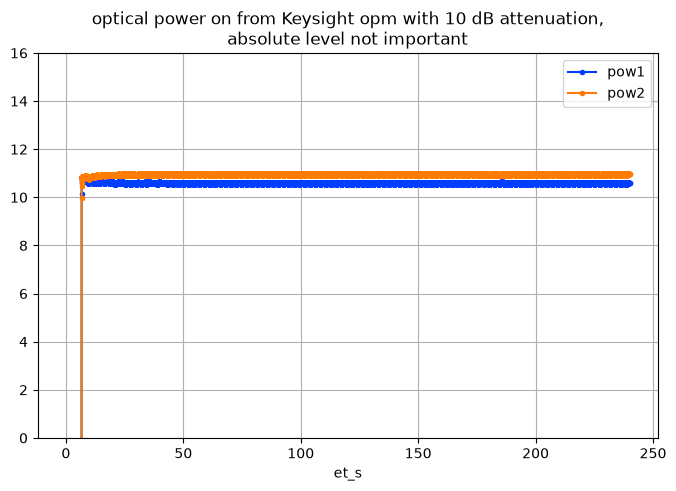

In [9]:
ycols=[f'pow{1+i}' for i in range(2*len(idx_tiles))]
fig,ax=plt.subplots(figsize=(8,5))
df_results.plot('et_s', ycols,marker='.',ax=ax)
ax.grid()
#ax.set_xlim((16.25,17))
ax.set_ylim((-0,16))
ax.set_title('optical power on from Keysight opm with 10 dB attenuation,\n absolute level not important ')
plt.show()

pptx.add_plot_slide('optical power on', fig, left=1, top=1.5, width=7)

## re-do optical power calibration

connect tile3 bank0 to Thorlabs OPM 
. reply 'y' or 'n', n: skip power cal:  y


You selected: Yes 
 do power cal
tile3, bank0, ch0, power_clm 8.044, power_opm 8.070067316, tap ratio correction 1.003240591248135
tile3, bank0, ch1, power_clm 8.148, power_opm 8.310488238, tap ratio correction 1.0199421008836524
tile3, bank0, ch2, power_clm 8.418, power_opm 8.363897726, tap ratio correction 0.993573025184129
tile3, bank0, ch3, power_clm 8.618, power_opm 8.60255379, tap ratio correction 0.998207680436296
tile3, bank0, ch4, power_clm 8.704, power_opm 8.907129616, tap ratio correction 1.0233375018382354
tile3, bank0, ch5, power_clm 8.604, power_opm 8.817472868, tap ratio correction 1.0248108865643886
tile3, bank0, ch6, power_clm 8.564, power_opm 8.668793736000001, tap ratio correction 1.012236540868753
tile3, bank0, ch7, power_clm 8.602, power_opm 8.718032390000001, tap ratio correction 1.0134890013950246


connect tile3 bank1 to Thorlabs OPM 
. reply 'y' or 'n', n: skip power cal:  y


You selected: Yes 
 do power cal
tile3, bank1, ch0, power_clm 8.646, power_opm 7.860441132, tap ratio correction 0.9091419306037474
tile3, bank1, ch1, power_clm 8.654, power_opm 8.105352708, tap ratio correction 0.9366018844464987
tile3, bank1, ch2, power_clm 8.636, power_opm 7.866696082, tap ratio correction 0.9109189534506716
tile3, bank1, ch3, power_clm 8.592, power_opm 7.804465852, tap ratio correction 0.9083409976722532
tile3, bank1, ch4, power_clm 8.658, power_opm 7.824995551999999, tap ratio correction 0.9037878900438899
tile3, bank1, ch5, power_clm 8.560, power_opm 7.81040024, tap ratio correction 0.9124299345794392
tile3, bank1, ch6, power_clm 8.458, power_opm 7.704224066, tap ratio correction 0.9108801213052731
tile3, bank1, ch7, power_clm 8.286, power_opm 7.419696264000001, tap ratio correction 0.8954497060101377


connect tile4 bank0 to Thorlabs OPM 
. reply 'y' or 'n', n: skip power cal:  y


You selected: Yes 
 do power cal
tile4, bank0, ch0, power_clm 8.792, power_opm 8.65564216, tap ratio correction 0.9844906915377616
tile4, bank0, ch1, power_clm 8.322, power_opm 8.348660914, tap ratio correction 1.0032036666666668
tile4, bank0, ch2, power_clm 8.284, power_opm 8.326045795999999, tap ratio correction 1.005075542732979
tile4, bank0, ch3, power_clm 8.440, power_opm 8.375765944, tap ratio correction 0.9923893298578197
tile4, bank0, ch4, power_clm 8.524, power_opm 8.610573226, tap ratio correction 1.010156408493665
tile4, bank0, ch5, power_clm 8.442, power_opm 8.529737964, tap ratio correction 1.0103930305614783
tile4, bank0, ch6, power_clm 8.482, power_opm 8.588279412, tap ratio correction 1.0125299943409571
tile4, bank0, ch7, power_clm 8.346, power_opm 8.563258873999999, tap ratio correction 1.026031497004553


connect tile4 bank1 to Thorlabs OPM 
. reply 'y' or 'n', n: skip power cal:  y


You selected: Yes 
 do power cal
tile4, bank1, ch0, power_clm 9.042, power_opm 8.14657267, tap ratio correction 0.900970213448352
tile4, bank1, ch1, power_clm 8.776, power_opm 7.990354858000001, tap ratio correction 0.9104779920237012
tile4, bank1, ch2, power_clm 8.810, power_opm 7.8219480820000005, tap ratio correction 0.8878488174801362
tile4, bank1, ch3, power_clm 8.682, power_opm 7.894603816000002, tap ratio correction 0.9093070509099288
tile4, bank1, ch4, power_clm 8.664, power_opm 7.878083921999999, tap ratio correction 0.9092894646814403
tile4, bank1, ch5, power_clm 8.586, power_opm 7.804305478000001, tap ratio correction 0.9089570787328209
tile4, bank1, ch6, power_clm 8.538, power_opm 7.573507911999999, tap ratio correction 0.887035360974467
tile4, bank1, ch7, power_clm 8.282, power_opm 7.274064516, tap ratio correction 0.8782980579570152
old pic tap ratios:  [0.0436, 0.0451, 0.0461, 0.0439, 0.0462, 0.0459, 0.0479, 0.0505, 0.0365, 0.0364, 0.0374, 0.0371, 0.0402, 0.0402, 0.0409,

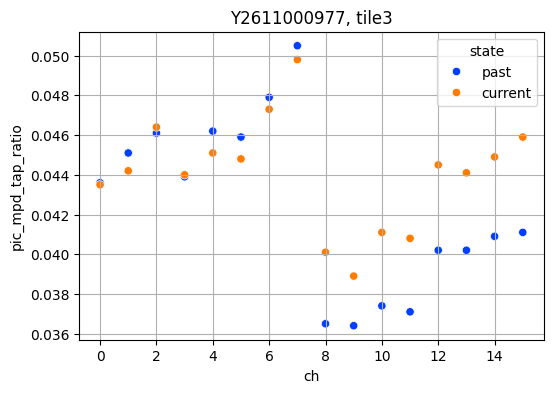

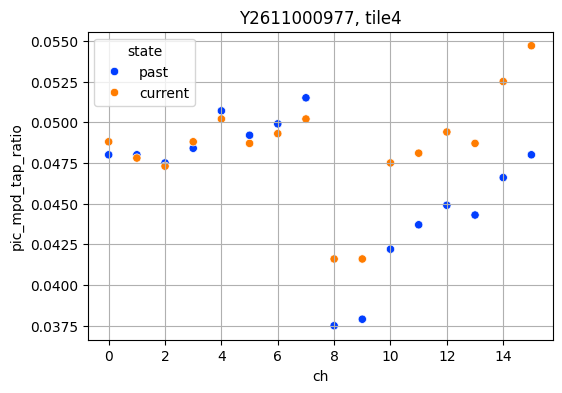

In [21]:
if bPowerCal==True:
    dict_tap_corr={}
    for idxTile in idx_tiles:
        tap_corr=[1]*16
        tile=tb.module.packages[0].tiles[idxTile]
        for bank, BANK_AB in enumerate(mca.ClmTile.Bank):
            mca.clm_lane_enable(tile,[0]*16)
            
            while True:
                response = input(f"connect tile{idxTile} bank{bank} to Thorlabs OPM \n. reply 'y' or 'n', n: skip power cal: ").strip().lower()
                if response in ['y', 'n']:
                    break
                print("Invalid input. Please type 'y' or 'n'.")
            
            if response == 'y':
                print("You selected: Yes \n do power cal")
                for ch in range(8):
                    chEnMask=[0]*16
                    chEnMask[8*bank+ch]=1
                    mca.clm_lane_enable(tile,chEnMask)
                    time.sleep(10)
                    Nsample=5
                    power_clm=0
                    power_opm=0
                    for j in range(Nsample):
                        monitors = tile.read_optical_power_monitors(BANK_AB)
                        power_clm+=monitors[ch]
                        power_opm+=opm_thorlab.get_power_mw()
                        time.sleep(3)
                    corr_tap=(power_opm/Nsample)/(power_clm*1e-3/Nsample)
                    tap_corr[bank*8+ch]=corr_tap
                    print(f'tile{idxTile}, bank{bank}, ch{ch}, power_clm {power_clm*1e-3/Nsample:.3f}, power_opm {power_opm/Nsample}, tap ratio correction {corr_tap}')
            else:
                print("You selected: No")    
                pass

        dict_tap_corr.update({idxTile:tap_corr}) 

    df_pic_taps=pd.DataFrame()
    cols=['tile','state','ch','pic_mpd_tap_ratio','corr_dB']
    tiles=[]
    states=[]
    chs=[]
    taps=[]
    corr_dBs=[]
    
    for idxTile in idx_tiles:
        tile=tb.module.packages[0].tiles[idxTile]
        fru_full=mca.get_fru_full(tile)
    
        tap_ratios_old=fru_full['pic_mpd_tap_ratios']
        tap_ratios_new=[1]*16
        for ch, tap_ratio in enumerate(tap_ratios_old):
            tap_ratios_new[ch]=round(tap_ratio/dict_tap_corr[idxTile][ch],4)
    
        print('old pic tap ratios: ', tap_ratios_old)
        print('new pic tap ratios: ', tap_ratios_new)
        
        tiles=tiles+[idxTile]*16
        states=states+['past']*16
        chs=chs+list(range(16))
        taps=taps+tap_ratios_old
        corr_dBs=corr_dBs+[0]*16
        
        tiles=tiles+[idxTile]*16
        states=states+['current']*16
        chs=chs+list(range(16))
        taps=taps+tap_ratios_new
        corr_dBs=corr_dBs+list(np.round(10*np.log10(1/np.array(tap_corr)),2))
        
        tile.flash_write_fru_optical_measurements(tap_ratios_new, fru_full['mux_mpd_tap_ratios'], [40]*16)
        
        fru_full.update({'pic_mpd_tap_ratios':tap_ratios_new})
        dict_fru_revised.update({idxTile:fru_full})

    for c, d in zip(cols,[tiles,states,chs,taps,corr_dBs]):
        df_pic_taps[c]=d

    dfg=df_pic_taps.groupby(by='tile')
    
    for tile,dfsub in dfg:
        fig,ax=plt.subplots(figsize=(6,4))
        sns.scatterplot(data=dfsub,x='ch',y='pic_mpd_tap_ratio',hue='state', palette='bright',ax=ax)
        ax.set_title(f'{sn}, tile{tile}')
        ax.grid(True)
        plt.show()
    
        pptx.add_plot_slide(f'{sn}, tile{tile}, pic mpd tap ratio', fig, left=1, top=1.5, width=7)    



## check clm power and frequency stability with all chs on

In [65]:
pptx=PresentationManager()

wait a bit for clm power to stabilize

....................................................................................................................................................................................0.01%,0.02%,0.04%,0.06%,0.08%,0.09%,0.11%,0.13%,0.14%,0.16%,0.18%,0.19%,0.21%,0.23%,0.24%,0.26%,0.28%,0.29%,0.31%,0.33%,0.35%,0.36%,0.38%,0.40%,0.41%,0.43%,0.45%,0.46%,0.48%,0.50%,0.51%,0.53%,0.55%,0.57%,0.58%,0.60%,0.62%,0.63%,0.65%,0.67%,0.68%,0.70%,0.72%,0.73%,0.75%,0.77%,0.79%,0.80%,0.82%,0.84%,0.85%,0.87%,0.89%,0.90%,0.92%,0.94%,0.95%,0.97%,0.99%,1.00%,1.02%,1.04%,1.06%,1.07%,1.09%,1.11%,1.12%,1.14%,1.16%,1.17%,1.19%,1.21%,1.22%,1.24%,1.26%,1.27%,1.29%,1.31%,1.33%,1.34%,1.36%,1.38%,1.39%,1.41%,1.43%,1.44%,1.46%,1.48%,1.49%,1.51%,1.53%,1.55%,1.56%,1.58%,1.60%,1.61%,1.63%,1.65%,1.66%,1.68%,1.70%,1.71%,1.73%,1.75%,1.77%,1.78%,1.80%,1.82%,1.83%,1.85%,1.87%,1.88%,1.90%,1.92%,1.93%,1.95%,1.97%,1.98%,2.00%,2.02%,2.04%,2.05%,2.07%,2.09%,2.10%,2.12%,2.14%,2.15%,2.17%,2.19%,2

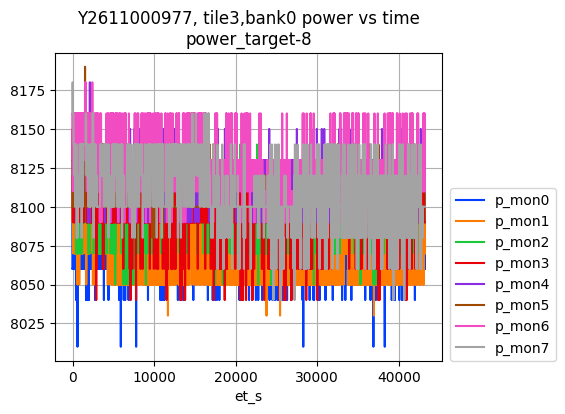

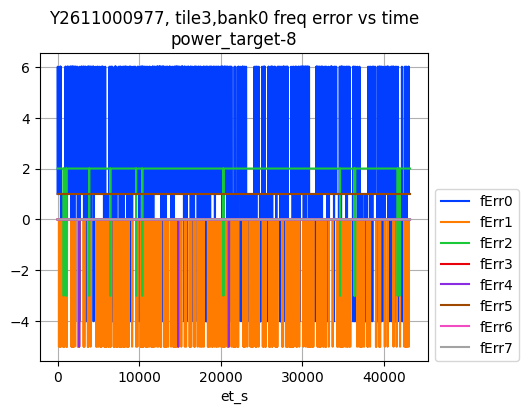

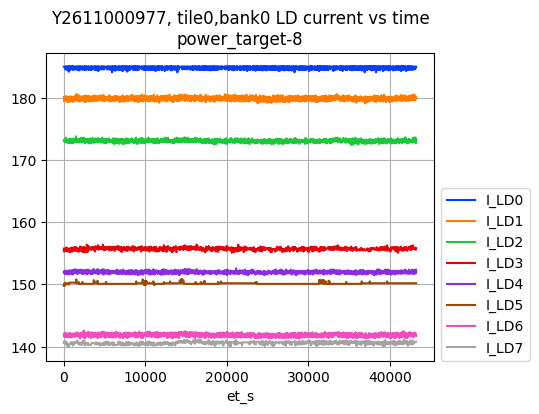

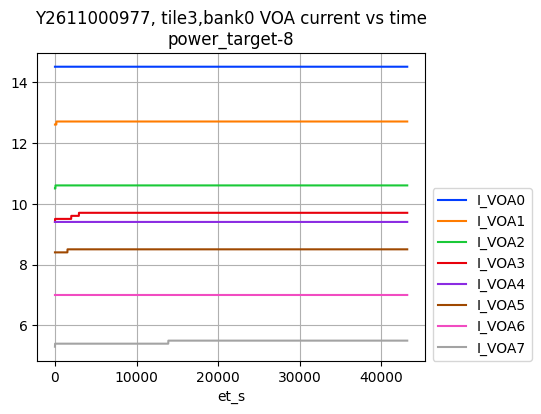

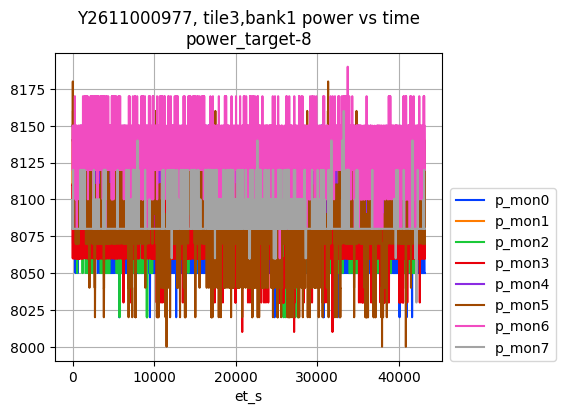

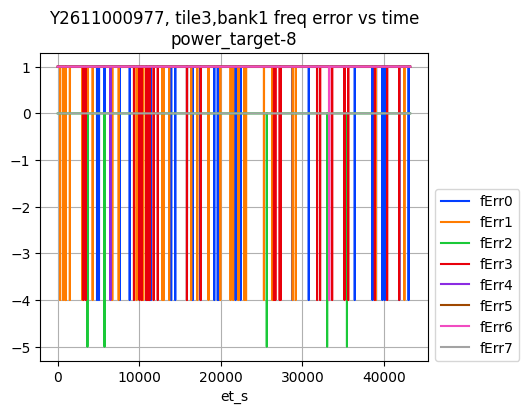

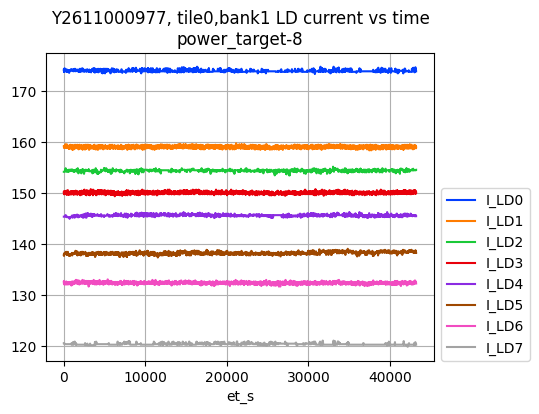

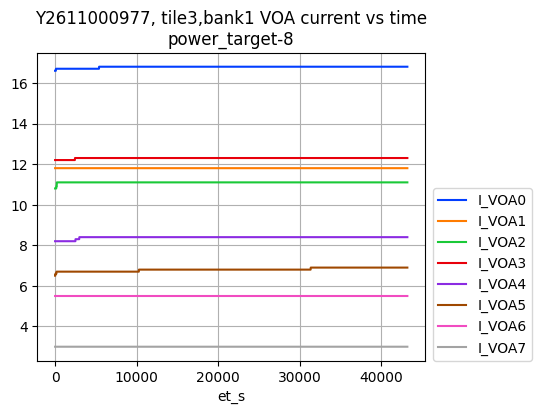

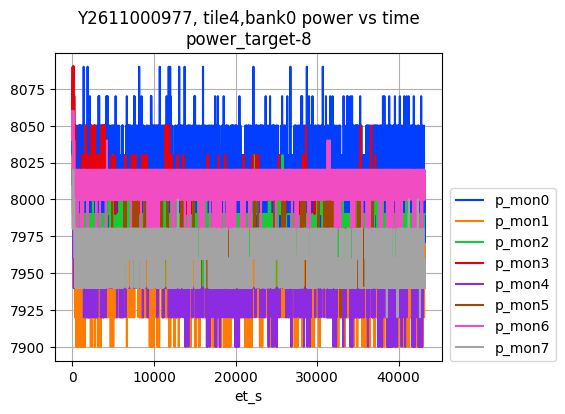

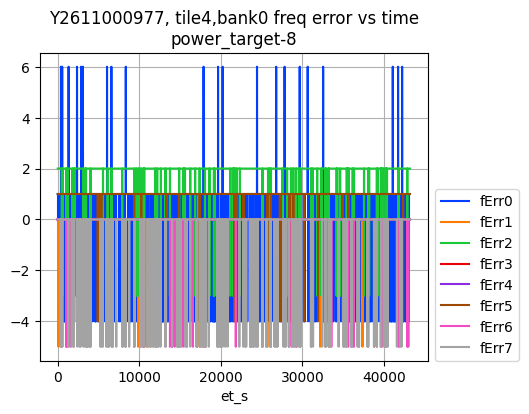

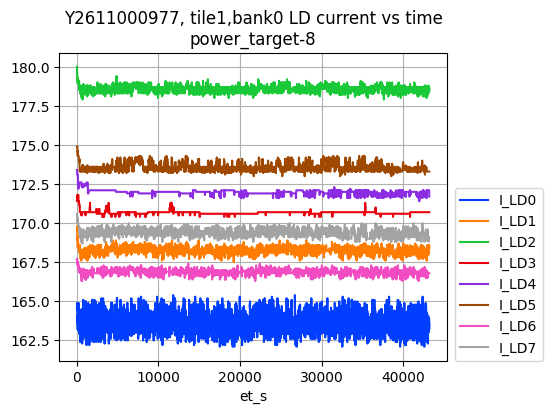

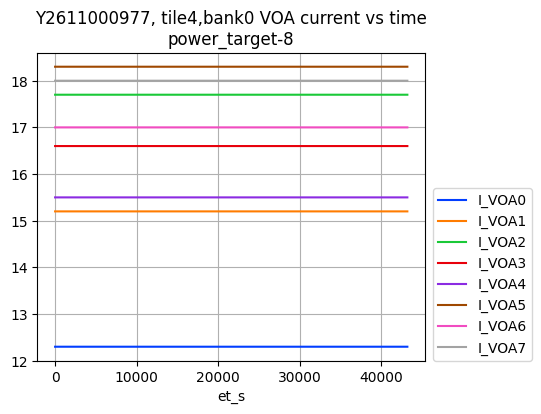

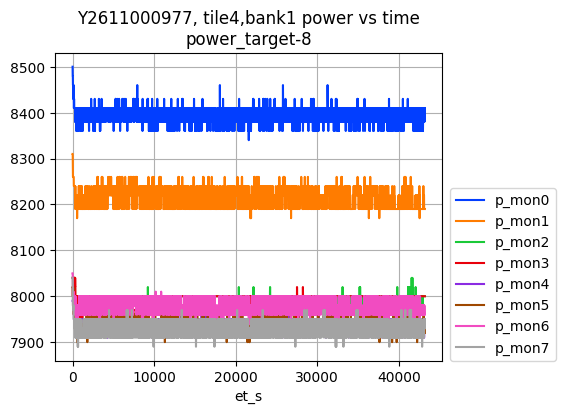

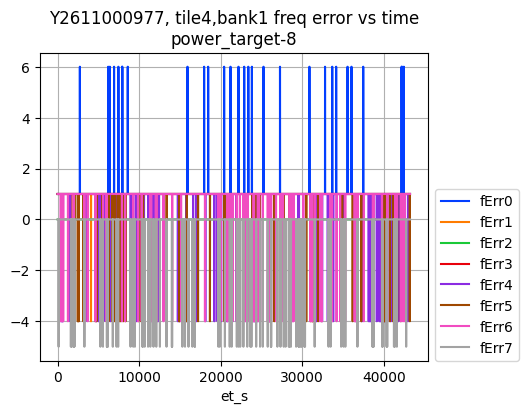

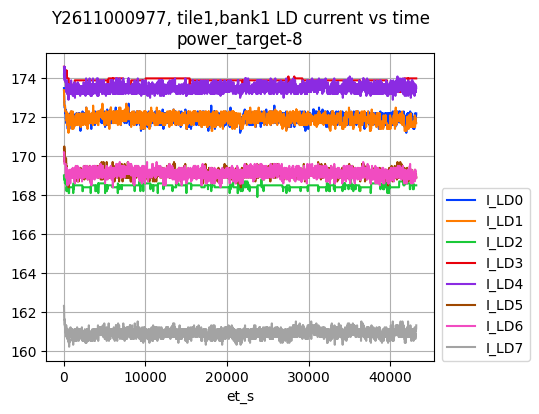

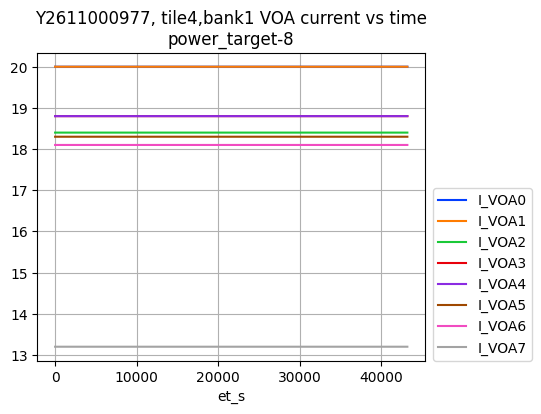

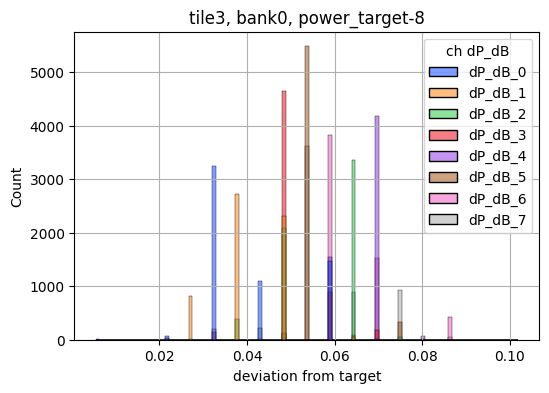

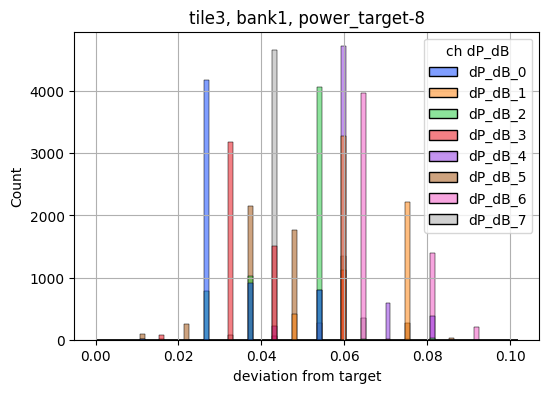

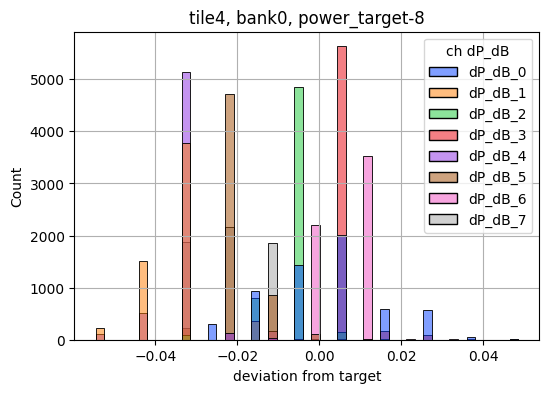

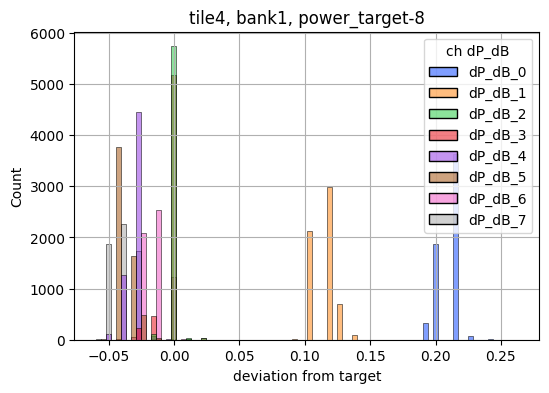

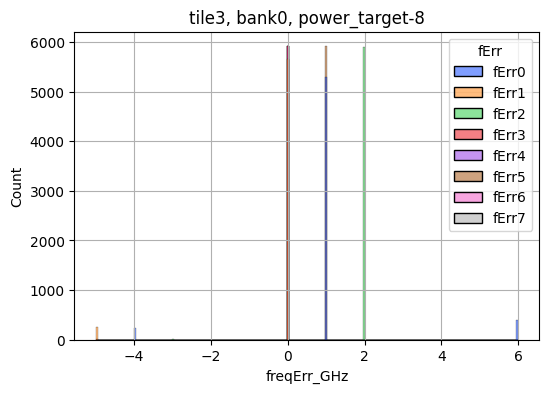

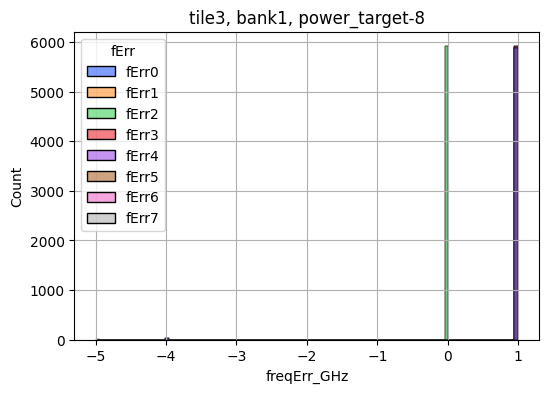

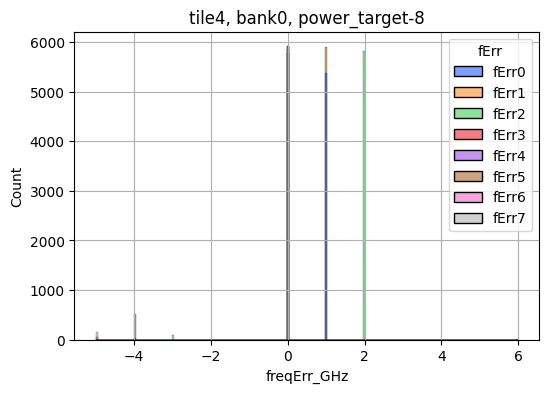

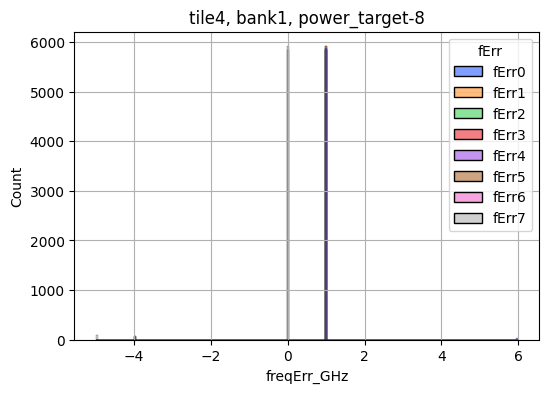

In [66]:
power_target=8
voa_dither_amp=0
mux_dither_amp=3
for power_target in [8]:
    note=f'power_target-{power_target}'
    for idxTile in idx_tiles:
        tile=tb.module.packages[0].tiles[idxTile]
        '''
        tile.write_dither_identification_amplitude(voa_dither_amp) # 850uA
        print(f'tile{idxTile} voa dither amp: ',tile.read_dither_identification_amplitude())
        
        tile.write_dither_identification_periods([0,0,0,0,5,6,8,11]) #Ch4 has divisor 5, Ch5 has 6
        print(f'tile{idxTile} voa dither period: ',tile.read_dither_identification_periods())
        '''
        # mca.optical_power_on(tile)
        mca.set_clm_output_targets(tile,freq_offset_targets=[0]*16,power_targets=[power_target]*16)
        mca.set_clm_control_config(tile,dither_period_s=2,kp_tpic=kps[0],kp_ld=kps[1],kp_voa=kps[2],amp_t_mux=mux_dither_amp,ALPHA_I_LD=0.5)
        
        time.sleep(0.05)
    
    
    duration_s=3600*12 # 5 minutes
    tiles=[]
    for i, idxTile in enumerate(idx_tiles):
        tile=tb.module.packages[0].tiles[idxTile]
        mca.clm_lane_enable(tile,[1]*16)    
        tiles.append(tb.module.packages[0].tiles[idxTile])   
        mca.set_clm_output_targets(tiles[i],freq_offset_targets=[0]*16,power_targets=[power_target]*16)
    
    time_init_stab=180
    t0=time.time()
    print('wait a bit for clm power to stabilize\n') 
    while time.time()-t0<time_init_stab:
        print(".",end='',flush=True)
        time.sleep(1) #
    
    rcds,cols=mca.get_clm_record(tiles, duration_s=duration_s,interval_s=3)
    
    df=pd.DataFrame(rcds,columns=cols)
    
    now = datetime.now()
    tstamp = now.strftime("%Y-%m-%d-%H-%M")
    filename_stab=f'{sn}_stability test_over_{duration_s}s_{tstamp}_{note}.csv'
    df.to_csv(filename_stab)
    
    #%%
    dfg=df.groupby(by=['tile','bank'])
    for (tile,bank), dfsub in dfg:
        fig,ax=plt.subplots(figsize=(5,4))
        dfsub.plot('et_s',['p_mon0', 'p_mon1', 'p_mon2', 'p_mon3', 'p_mon4', 'p_mon5', 'p_mon6','p_mon7'],ax=ax)
        ax.grid(True)
        ax.set_title(f'{sn}, tile{idx_tiles[tile]},bank{bank} power vs time\n{note}')
        ax.legend(loc=(1.02,0))
        plt.show()
        
        pptx.add_plot_slide(f'{sn}, tile{idx_tiles[tile]},bank{bank}, {note}', fig, left=1, top=1.5, width=7)
    
        fig,ax=plt.subplots(figsize=(5,4))
        dfsub.plot('et_s',['fErr0', 'fErr1','fErr2', 'fErr3', 'fErr4', 'fErr5', 'fErr6', 'fErr7'],ax=ax)
        ax.grid(True)
        ax.set_title(f'{sn}, tile{idx_tiles[tile]},bank{bank} freq error vs time\n{note}')
        ax.legend(loc=(1.02,0))
        plt.show()
        
        pptx.add_plot_slide(f'{sn}, tile{idx_tiles[tile]},bank{bank}, {note}', fig, left=1, top=1.5, width=7)
    
    
        fig,ax=plt.subplots(figsize=(5,4))
        dfsub.plot('et_s',['I_LD0',
               'I_LD1', 'I_LD2', 'I_LD3', 'I_LD4', 'I_LD5', 'I_LD6', 'I_LD7'],ax=ax)
        ax.grid(True)
        ax.set_title(f'{sn}, tile{tile},bank{bank} LD current vs time\n{note}')
        ax.legend(loc=(1.02,0))
        plt.show()
    
        pptx.add_plot_slide(f'{sn}, tile{tile},bank{bank}, {note}', fig, left=1, top=1.5, width=7)
    
        fig,ax=plt.subplots(figsize=(5,4))
        dfsub.plot('et_s',['I_VOA0','I_VOA1', 'I_VOA2', 'I_VOA3', 'I_VOA4', 'I_VOA5', 'I_VOA6', 'I_VOA7'],ax=ax)
        ax.grid(True)
        ax.set_title(f'{sn}, tile{idx_tiles[tile]},bank{bank} VOA current vs time\n{note}')
        ax.legend(loc=(1.02,0))
        plt.show()
        
        pptx.add_plot_slide(f'{sn}, tile{tile},bank{bank}, {note}', fig, left=1, top=1.5, width=7)

    for i in range(8):
        df[f'dP_dB_{i}']=10*np.log10(df[f'p_mon{i}']/df[f'p_set{i}']/1000)
    melted_df = pd.melt(
        df, 
        id_vars=['tile','bank','et_s'], 
        value_vars=[f'dP_dB_{i}' for i in range(8)],
        var_name='ch dP_dB', 
        value_name='deviation from target'
    )
    
    melted_df_fErr = pd.melt(
        df, 
        id_vars=['tile','bank','et_s'], 
        value_vars=[f'fErr{i}' for i in range(8)],
        var_name='fErr', 
        value_name='freqErr_GHz'
    )
    
    dfg=melted_df.groupby(by=['tile','bank'])
    
    for (tile,bank),dfsub in dfg:
        fig,ax=plt.subplots(figsize=(6,4))
        sns.histplot(data=dfsub,x='deviation from target',hue='ch dP_dB', palette='bright',ax=ax)
        ax.set_title(f'tile{idx_tiles[tile]}, bank{bank}, {note}')
        ax.grid(True)
        plt.show()
    
        pptx.add_plot_slide(f'{sn}, tile{tile},bank{bank}, ch power histogram', fig, left=1, top=1.5, width=7)
    
    
    dfg_ferr=melted_df_fErr.groupby(by=['tile','bank'])
    for (tile,bank),dfsub in dfg_ferr:
    
        fig,ax=plt.subplots(figsize=(6,4))
        sns.histplot(data=dfsub,x='freqErr_GHz',hue='fErr', palette='bright',ax=ax)
        ax.set_title(f'tile{idx_tiles[tile]}, bank{bank}, {note}')
        ax.grid(True)
        plt.show()
    
        pptx.add_plot_slide(f'{sn}, tile{tile},bank{bank}, ch freqErr histogram, {note}', fig, left=1, top=1.5, width=7)

## update fru data 

In [16]:
for idxTile, d_fru in dict_fru_revised.items():
    str_bullets=[]
    for k in ['serial_number', 'temp_pic', 'temp_mux']:
        str_bullets.append(': '.join([k,str(d_fru[k])]))
    for k in ['power_targets', 'freq_error_targets','voa_currents', 'bias_currents', 'pic_mpd_tap_ratios', 'mux_mpd_tap_ratios']:
        str_bullets.append(': '.join([k,str(d_fru[k])]))

    pptx.add_bullet_slide(f"tile{idxTile} revised config info", str_bullets,font_size=14)

export_to_yaml_file(datadir,dict_fru_revised,sn=sn,operator=operator)

0

## save test report to pptx

In [69]:
now = datetime.now()
tstamp = now.strftime("%Y-%m-%d-%H-%M")
pptx.save(datadir+'\\'+f"{sn} _{note}_ppt_{tstamp}.pptx")

Presentation saved as C:\Users\MountainViewLabUser\clm_screen_n_debug\Y2611000977_2026-07-25\Y2611000977 _power_target-8_ppt_2026-07-28-09-15.pptx


In [68]:
note

'power_target-8'

## close down

In [67]:
mca.shut_down_test_board_nicely(tb)
#tb.close()

0

In [14]:
tile=tb.module.packages[0].tiles[3]

In [33]:
tile.write_dither_identification_amplitude(200) # 850uA
tile.read_dither_identification_amplitude()

200

In [34]:
tile.write_dither_identification_periods([0,0,0,0,5,6,8,11]) #Ch4 has divisor 5, Ch5 has 6
tile.read_dither_identification_periods()

(0, 0, 0, 0, 5, 6, 8, 11)

## additional tests
### opm recorded per ch optical stability


In [ ]:
chs_each_port=[4,7]
p_tgts=[8,10]
#kps_n_ditheramps=[[0.2,0.2,0.2,3],[0.2,0.2,0.2,0]]
kps_n_ditheramps=[[0.2,0.2,0.2,3]]
duration_s=240


now = datetime.now()
tstamp = now.strftime("%Y-%m-%d-%H-%M")

for ch in chs_each_port:
    chMask=[0]*16
    chMask[ch]=1
    chMask[ch+8]=1
    
    for p_tgt in p_tgts:
        for kp_dither in kps_n_ditheramps:
            t0=time.time()
            for idxTile in idx_tiles:
                tile=tb.module.packages[0].tiles[idxTile]
                    
                mca.clm_lane_enable(tile,chMask)
                mca.set_clm_output_targets(tile,freq_offset_targets=[0]*16,power_targets=[p_tgt]*16)
                mca.set_clm_control_config(tile,dither_period_s=2,kp_tpic=kp_dither[0],kp_ld=kp_dither[1],kp_voa=kp_dither[2],amp_t_mux=kp_dither[3],ALPHA_I_LD=0.5)

                for bank in mca.ClmTile.Bank:
                    tile.write_mux_dither_enable(bank, True) # muxDitherMode = True or False

                filename_log='_'.join([sn,'opm log',f'ch{ch}',f'p-tgt{p_tgt}',f'kp_tpic_{kp_dither[0]}',f'kp_ld_{kp_dither[1]}',
                                       f'kp_voa_{kp_dither[2]}',f'dither_{kp_dither[3]}',tstamp,'.csv'])
                
                executor = concurrent.futures.ThreadPoolExecutor(max_workers=1)
                
                future_data = executor.submit(
                    opm.capture_power_log,
                    active_channels, 
                    avg_time_ms,  # avg_time_ms
                    duration_s    # duration_s (Running for 5 seconds to demonstrate the background work)
                )
                
                print(f'ch{ch} on, p_tgt {p_tgt}, {str(kp_dither)}')
                
                try:
                    while not future_data.done():
                        et=time.time()-t0
                        if abs(et-duration_s/2)<2:
                            print('mux dither off')
                            for bank in mca.ClmTile.Bank:
                                tile.write_mux_dither_enable(bank, False) # muxDitherMode = True or False
                            
                        #print("wait for opm log to complete, elapsed time: ",round(et,0))
                        print(".",end='',flush=True)
                       time.sleep(1) # Simulate doing other work
                        
                    df_results = future_data.result()
                    print("\n[Main] Background task complete! Data acquired:")
                    
                    # Save to CSV
                    df_results.to_csv(datadir+'\\'+filename_log, index=False)
                    
                    # plot and generate slide
                    fig,ax=plt.subplots(figsize=(5,3))
                    ycols=[f'pow{5+i}' for i in range(2*len(idx_tiles))]
                    df_results.plot('et_s', ycols,ax=ax)
                    ax.grid()
                    ax.set_ylim((-0,13))
                    ax.set_title(filename_log[0:len(filename_log)-4])
                    plt.show()
                    
                    pptx.add_plot_slide(filename_log, fig, left=1, top=1.5, width=7)
                    
                    
                except Exception as e:
                    print(f"[Main] The background thread encountered an error: {e}")
                    
                finally:
                    # Clean up the thread pool
                    executor.shutdown()
                    #opm.disconnect()
                    print("done.")        

ch4 on, p_tgt 8, [0.2, 0.2, 0.2, 3]
[Main] The background thread encountered an error: [WinError 10054] An existing connection was forcibly closed by the remote host
done.
ch4 on, p_tgt 10, [0.2, 0.2, 0.2, 3]
[Main] The background thread encountered an error: [WinError 10054] An existing connection was forcibly closed by the remote host
done.
ch7 on, p_tgt 8, [0.2, 0.2, 0.2, 3]
[Main] The background thread encountered an error: [WinError 10054] An existing connection was forcibly closed by the remote host
done.
ch7 on, p_tgt 10, [0.2, 0.2, 0.2, 3]
[Main] The background thread encountered an error: [WinError 10054] An existing connection was forcibly closed by the remote host
done.


## control channel enable/disable

In [36]:
chMask=[1,1,1,1,1,1,1,1]+[1,1,1,1,1,1,1,1]
#chMask=[0]*16
mca.clm_lane_enable(tile,chMask)

0

## test checking back reflection to mux MPD leakage

In [24]:
tile3=tb.module.packages[0].tiles[3]
tile4=tb.module.packages[0].tiles[4]

In [65]:
tile_on_offs=[[1,1],[0,1],[1,0],[0,0]]
sample_N=150
sample_interval=2
pausetime=60
cols=['et_s','i_sample','on-off_tile3','on-off_tile4']+[f'pow_mux_tile3_{i}' for i in range(16)]+[f'pow_mux_tile4_{i}' for i in range(16)]

In [76]:
t0=time.time()
rcds=[]
for n,tile_on_off in  enumerate(tile_on_offs):
    mca.clm_lane_enable(tile3,[tile_on_off[0]]*16)
    mca.clm_lane_enable(tile4,[tile_on_off[1]]*16)
    time.sleep(pausetime)

    for i in range(sample_N):
        rcd=[None]*len(cols)
        rcd[0]=round(time.time()-t0,1)
        rcd[1]=n*sample_N+i
        rcd[2]=tile_on_off[0]
        rcd[3]=tile_on_off[1]

        rcd[4:4+16]=tile3.read_aux_optical_power_monitors(mca.ClmTile.Bank.BANK_A)+tile3.read_aux_optical_power_monitors(mca.ClmTile.Bank.BANK_B)
        rcd[20:20+16]=tile4.read_aux_optical_power_monitors(mca.ClmTile.Bank.BANK_A)+tile4.read_aux_optical_power_monitors(mca.ClmTile.Bank.BANK_B) 

        rcds.append(rcd)
        print(".",end='',flush=True)        
        time.sleep(sample_interval)
    

........................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................................

In [77]:
df=pd.DataFrame(rcds,columns=cols)

In [78]:
df.columns

Index(['et_s', 'i_sample', 'on-off_tile3', 'on-off_tile4', 'pow_mux_tile3_0',
       'pow_mux_tile3_1', 'pow_mux_tile3_2', 'pow_mux_tile3_3',
       'pow_mux_tile3_4', 'pow_mux_tile3_5', 'pow_mux_tile3_6',
       'pow_mux_tile3_7', 'pow_mux_tile3_8', 'pow_mux_tile3_9',
       'pow_mux_tile3_10', 'pow_mux_tile3_11', 'pow_mux_tile3_12',
       'pow_mux_tile3_13', 'pow_mux_tile3_14', 'pow_mux_tile3_15',
       'pow_mux_tile4_0', 'pow_mux_tile4_1', 'pow_mux_tile4_2',
       'pow_mux_tile4_3', 'pow_mux_tile4_4', 'pow_mux_tile4_5',
       'pow_mux_tile4_6', 'pow_mux_tile4_7', 'pow_mux_tile4_8',
       'pow_mux_tile4_9', 'pow_mux_tile4_10', 'pow_mux_tile4_11',
       'pow_mux_tile4_12', 'pow_mux_tile4_13', 'pow_mux_tile4_14',
       'pow_mux_tile4_15'],
      dtype='str')

In [79]:
now = datetime.now()
tstamp = now.strftime("%Y-%m-%d-%H-%M")
df.to_csv(datadir+'\\'+f"{sn} _tile3-4_mux_mpd_X-talk_ppt_{tstamp}.csv")

In [80]:
dfg_mean=df.groupby(by=['on-off_tile3', 'on-off_tile4']).mean()
dfg_std=df.groupby(by=['on-off_tile3', 'on-off_tile4']).std()

In [84]:
print('tile3:' ,tile3.read_vendor_part_number())
print('tile4:' ,tile4.read_vendor_part_number())

tile3: 2120000174      
tile4: 2120000174      


In [81]:
dfg_std[['pow_mux_tile3_1', 'pow_mux_tile3_2', 'pow_mux_tile3_3',
       'pow_mux_tile3_4', 'pow_mux_tile3_5', 'pow_mux_tile3_6',
       'pow_mux_tile3_7', 'pow_mux_tile3_8', 'pow_mux_tile3_9',
       'pow_mux_tile3_10', 'pow_mux_tile3_11', 'pow_mux_tile3_12',
       'pow_mux_tile3_13', 'pow_mux_tile3_14', 'pow_mux_tile3_15']].T

on-off_tile3             0                      1            
on-off_tile4             0          1           0           1
pow_mux_tile3_1   0.000000   9.924998   39.230632  163.915786
pow_mux_tile3_2   0.000000   4.349908   31.559042  117.399507
pow_mux_tile3_3   0.000000   8.018156   47.723851   42.701031
pow_mux_tile3_4   0.000000  10.467591   37.913359  199.780069
pow_mux_tile3_5   0.000000   5.243084   39.727033   53.144689
pow_mux_tile3_6   0.000000   9.188311   46.756066   64.482937
pow_mux_tile3_7   0.000000   7.333842   41.736630  186.085304
pow_mux_tile3_8   0.000000   6.847982   60.128461   53.549659
pow_mux_tile3_9   0.000000   8.798007   63.114682   47.406519
pow_mux_tile3_10  0.000000   6.474524   62.511064   62.284223
pow_mux_tile3_11  0.000000   7.301742   45.371940   45.622711
pow_mux_tile3_12  0.000000   9.911465   41.194741   38.702444
pow_mux_tile3_13  0.000000   3.232940  183.276469  169.595136
pow_mux_tile3_14  1.150819   4.568152   34.206963   52.924157
pow_mux_tile3_15  1.632993   7.230312   61.664605   92.574512

In [82]:
dfg_std[['pow_mux_tile4_0', 'pow_mux_tile4_1', 'pow_mux_tile4_2',
       'pow_mux_tile4_3', 'pow_mux_tile4_4', 'pow_mux_tile4_5',
       'pow_mux_tile4_6', 'pow_mux_tile4_7', 'pow_mux_tile4_8',
       'pow_mux_tile4_9', 'pow_mux_tile4_10', 'pow_mux_tile4_11',
       'pow_mux_tile4_12', 'pow_mux_tile4_13', 'pow_mux_tile4_14',
       'pow_mux_tile4_15']].T

on-off_tile3        0                     1            
on-off_tile4        0          1          0           1
pow_mux_tile4_0   0.0  66.972264   0.000000   92.279824
pow_mux_tile4_1   0.0  33.894758   2.301638   91.294175
pow_mux_tile4_2   0.0  45.213092  10.185967  154.977966
pow_mux_tile4_3   0.0  55.568810   4.232610   92.412459
pow_mux_tile4_4   0.0  43.534861   4.632344  122.263587
pow_mux_tile4_5   0.0  37.455776   8.521325   40.428355
pow_mux_tile4_6   0.0  42.577788  10.355861   50.941428
pow_mux_tile4_7   0.0  35.162836  13.026389  142.499013
pow_mux_tile4_8   0.0  47.291566  12.846365   51.834360
pow_mux_tile4_9   0.0  38.245001   7.283336   54.702122
pow_mux_tile4_10  0.0  47.091752   6.020101   60.064134
pow_mux_tile4_11  0.0  32.975416  11.348457   45.185227
pow_mux_tile4_12  0.0  38.485013  10.241819   44.998683
pow_mux_tile4_13  0.0  59.097462   9.293620   55.144958
pow_mux_tile4_14  0.0  33.154847   8.650303   36.529293
pow_mux_tile4_15  0.0  38.892728   1.632993  110.556473

In [75]:
df.iloc[0:10]['pow_mux_tile4_1']

0    12960
1    12960
2    12960
3    12960
4    12960
5    12960
6    12960
7    12960
8    12960
9    12960
Name: pow_mux_tile4_1, dtype: int64

## get current clm status

In [16]:
'''
print out current status
'''

for idxTile in idx_tiles:
    tile=tb.module.packages[0].tiles[idxTile]

    print(f'tile{idxTile} A chEnMask: ',tile.read_lane_enables(mca.ClmTile.Bank.BANK_A))
    print(f'tile{idxTile} B chEnMask: ',tile.read_lane_enables(mca.ClmTile.Bank.BANK_B))
    
    print(f'tile{idxTile} A VOA bias: ',tile.read_aux_bias_current_monitors(mca.ClmTile.Bank.BANK_A))
    print(f'tile{idxTile} B VOA bias: ',tile.read_aux_bias_current_monitors(mca.ClmTile.Bank.BANK_B))
    
    print(f'tile{idxTile} A LD bias: ',tile.read_bias_current_monitors(mca.ClmTile.Bank.BANK_A))
    print(f'tile{idxTile} B LD bias: ',tile.read_bias_current_monitors(mca.ClmTile.Bank.BANK_B))
    
    print(f'tile{idxTile} A power: ',tile.read_optical_power_monitors(mca.ClmTile.Bank.BANK_A))
    print(f'tile{idxTile} B power: ',tile.read_optical_power_monitors(mca.ClmTile.Bank.BANK_B))

'''
get faults
'''
'''
for idxTile in idx_tiles:
    tile=tb.module.packages[0].tiles[idxTile]
    print(idxTile,': ',mca.get_faults(tile))
'''

tile3 A chEnMask:  [True, True, True, True, True, True, True, True]
tile3 B chEnMask:  [True, True, True, True, True, True, True, True]
tile3 A VOA bias:  [3.9, 3.6, 2.4, 2.1, 1.9, 1.6, 0.7, 0.0]
tile3 B VOA bias:  [6.5, 3.6, 2.8, 3.6, 1.6, 0.2, 0.2, 0.0]
tile3 A LD bias:  [185.0, 185.0, 178.5, 161.9, 158.9, 155.6, 148.3, 145.7]
tile3 B LD bias:  [179.1, 164.4, 159.4, 155.7, 151.0, 141.8, 137.1, 126.5]
tile3 A power:  [11700, 11960, 11700, 11720, 11920, 11620, 11860, 11790]
tile3 B power:  [11870, 11720, 11750, 11710, 11680, 11670, 11730, 11020]
tile4 A chEnMask:  [True, True, True, True, True, True, True, True]
tile4 B chEnMask:  [True, True, True, True, True, True, True, True]
tile4 A VOA bias:  [4.3, 6.1, 7.6, 7.8, 6.6, 8.4, 7.4, 7.6]
tile4 B VOA bias:  [11.5, 10.6, 8.1, 9.1, 8.9, 8.6, 7.8, 4.9]
tile4 A LD bias:  [178.0, 181.3, 185.0, 183.5, 185.0, 185.0, 177.8, 178.8]
tile4 B LD bias:  [185.0, 183.4, 178.3, 185.0, 184.1, 181.1, 180.1, 172.8]
tile4 A power:  [11940, 11840, 11770, 11

"\nfor idxTile in idx_tiles:\n    tile=tb.module.packages[0].tiles[idxTile]\n    print(idxTile,': ',mca.get_faults(tile))\n"

In [41]:
print('tile3, A: ',tile3.read_aux_optical_power_monitors(mca.ClmTile.Bank.BANK_A))
print('tile3, B: ',tile3.read_aux_optical_power_monitors(mca.ClmTile.Bank.BANK_B))
print('tile4, A: ',tile4.read_aux_optical_power_monitors(mca.ClmTile.Bank.BANK_A))
print('tile4, B: ',tile4.read_aux_optical_power_monitors(mca.ClmTile.Bank.BANK_B))

tile3, A:  [13020, 13220, 14030, 13650, 13300, 13220, 13130, 12530]
tile3, B:  [14750, 14430, 14430, 14360, 14140, 13930, 13530, 12460]
tile4, A:  [13030, 13270, 13150, 13070, 12840, 12860, 13240, 13320]
tile4, B:  [14860, 14310, 14430, 13800, 14010, 13800, 14090, 13910]


In [40]:
mca.clm_lane_enable(tile4,[1]*16)

0

In [39]:
1290/14900

0.08657718120805369